# Check generated data for the given dataset_id

## Tools

In [ ]:
import sys
from pathlib import Path
import zipfile 
import numpy as np
from PIL import Image
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (16,4)

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[2]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

In [13]:
def open_zip(name, data_dir):
    z = zipfile.ZipFile(data_dir / name)
    print(f'Loaded {name}: {len(z.namelist()):,} files')
    return z


def read_image(fname, img_zip):
    png_name = fname + '.png'
    with img_zip.open(png_name) as f:
        return Image.open(f).convert('RGB')


def read_labels(fname, lbl_zip, mask_zip):
    npz_name = fname + '.npz'
    
    # --- instance & type maps
    if lbl_zip is not None:
        with lbl_zip.open(npz_name) as f:
            arrs = np.load(f)
            inst_sp = sparse.csr_matrix((arrs['inst_map_data'],
                                        arrs['inst_map_indices'],
                                        arrs['inst_map_indptr']),
                                        shape=tuple(arrs['inst_map_shape']))
            type_sp = sparse.csr_matrix((arrs['type_map_data'],
                                        arrs['type_map_indices'],
                                        arrs['type_map_indptr']),
                                        shape=tuple(arrs['type_map_shape']))
            inst = inst_sp.toarray().astype(np.int32)
            typ  = type_sp.toarray().astype(np.int32)
    else:
        inst = None
        typ = None
    
    # --- cell-ID mask
    with mask_zip.open(npz_name) as f:
        cid = sparse.load_npz(f).toarray().astype(np.int32)
    return inst, typ, cid


def show_patch(patch_id, img_zip, lbl_zip, mask_zip):

    img  = read_image(patch_id, img_zip)
    inst, typ, cid = read_labels(patch_id, lbl_zip, mask_zip)

    print('Shapes:', 
          'img', img.size[::-1], 
          '| inst_map', inst.shape if inst is not None else None, 
          '| type_map', typ.shape if typ is not None else None,
          '| cell_id_mask', cid.shape)


    if inst is not None and typ is not None:
        fig, ax = plt.subplots(1, 4, figsize=(16,4))
        ax[0].imshow(img)
        ax[0].set_title('Image')
        ax[1].imshow(inst, cmap='nipy_spectral')
        ax[1].set_title('Instance map')
        ax[2].imshow(typ,  cmap='tab20');  ax[2].set_title('Type map')
        ax[3].imshow(cid,  cmap='viridis');ax[3].set_title('Cell-ID mask')
        for a in ax: 
            a.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        fig, ax = plt.subplots(1, 2, figsize=(8,4))
        ax[0].imshow(img)
        ax[0].set_title('Image')
        ax[1].imshow(cid,  cmap='viridis');ax[1].set_title('Cell-ID mask')
        for a in ax: 
            a.axis('off')
        plt.tight_layout()
        plt.show()

    return img, inst, typ, cid


def str_cell_id(cell_id: int) -> str:
    """Transforms an integer cell ID into an Xenium Explorer alphabetical cell id
    E.g., str_cell_id(10001) = 'aaaachba-1'"""
    cell_id -= 1 # Shift by 1 to avoid having 0 as a cell ID because of background
    coefs = []
    for _ in range(8):
        cell_id, coef = divmod(cell_id, 16)
        coefs.append(coef)
    return "".join([chr(97 + coef) for coef in coefs][::-1]) + "-1"

## ds_ct1_20x_224_o112

In [5]:
dataset_id = 'ds_ct1_20x_224_o112'

In [11]:
data_dir = get_full_path('train', 'datasets', dataset_id)
img_zip = open_zip('images.zip', data_dir)
#lbl_zip = open_zip('labels.zip', data_dir)
lbl_zip = None
mask_zip = open_zip('masks_cell_ids_nuclei.zip', data_dir)
cell_count = pd.read_csv(data_dir / 'cell_count.csv')
types = pd.read_csv(data_dir / 'types.csv')
patch_metrics = pd.read_csv(data_dir / 'patch_metrics.csv')

Loaded images.zip: 467,888 files
Loaded masks_cell_ids_nuclei.zip: 467,888 files


In [32]:
# Chek same len for all data
assert len(img_zip.namelist()) == len(mask_zip.namelist()) == len(cell_count) == len(types) == len(patch_metrics)
print('All data files have the same number of patches:', len(img_zip.namelist()))

All data files have the same number of patches: 467888


In [8]:
cell_count

,patch_id,T_NK,B_Plasma,Myeloid,Blood_vessel,Fibroblast_Myofibroblast,Epithelial,Specialized,Melanocyte,Unknown
0,breast_s0_62,0,0,0,1,0,0,0,0,0
1,breast_s0_63,0,0,0,1,0,0,0,0,0
2,breast_s0_265,1,0,0,0,0,1,0,0,0
3,breast_s0_266,3,1,1,0,0,1,0,0,0
4,breast_s0_267,3,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
467883,cervix_s0_34044,0,0,0,0,5,0,0,0,13
467884,cervix_s0_34045,2,0,0,0,8,0,0,0,17
467885,cervix_s0_34046,2,0,0,0,4,0,0,0,9
467886,cervix_s0_34047,0,0,0,0,1,1,0,0,4


In [9]:
types

,patch_id,type
0,breast_s0_62,Breast
1,breast_s0_63,Breast
2,breast_s0_265,Breast
3,breast_s0_266,Breast
4,breast_s0_267,Breast
...,...,...
467883,cervix_s0_34044,Cervix
467884,cervix_s0_34045,Cervix
467885,cervix_s0_34046,Cervix
467886,cervix_s0_34047,Cervix


In [10]:
patch_metrics

,slide_id,patch_id,x_min,y_min,x_max,y_max
0,breast_s0,breast_s0_62,6944,0,7168,224
1,breast_s0,breast_s0_63,7056,0,7280,224
2,breast_s0,breast_s0_265,5488,112,5712,336
3,breast_s0,breast_s0_266,5600,112,5824,336
4,breast_s0,breast_s0_267,5712,112,5936,336
...,...,...,...,...,...,...
467883,cervix_s0,cervix_s0_34044,4928,22400,5152,22624
467884,cervix_s0,cervix_s0_34045,5040,22400,5264,22624
467885,cervix_s0,cervix_s0_34046,5152,22400,5376,22624
467886,cervix_s0,cervix_s0_34047,5264,22400,5488,22624


Shapes: img (224, 224) | inst_map None | type_map None | cell_id_mask (224, 224)


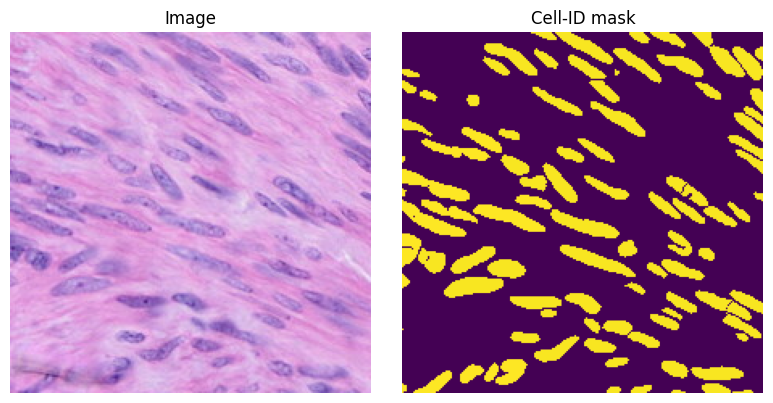

In [21]:
patch_id = "cervix_s0_14400"
img, inst, typ, cid = show_patch(patch_id, img_zip, lbl_zip, mask_zip)

In [22]:
np.array(img)

array([[[212, 167, 224],
        [208, 160, 220],
        [207, 157, 218],
        ...,
        [208, 153, 218],
        [212, 157, 222],
        [212, 160, 224]],

       [[221, 165, 228],
        [215, 155, 219],
        [210, 154, 217],
        ...,
        [198, 142, 207],
        [204, 149, 216],
        [208, 156, 222]],

       [[225, 160, 226],
        [223, 154, 221],
        [224, 159, 225],
        ...,
        [198, 141, 209],
        [200, 143, 212],
        [204, 149, 216]],

       ...,

       [[189, 126, 207],
        [195, 130, 210],
        [204, 137, 214],
        ...,
        [228, 174, 232],
        [228, 178, 237],
        [226, 179, 234]],

       [[198, 131, 208],
        [202, 134, 209],
        [208, 137, 213],
        ...,
        [227, 171, 232],
        [226, 174, 236],
        [223, 173, 234]],

       [[193, 123, 196],
        [204, 132, 205],
        [211, 139, 213],
        ...,
        [224, 168, 231],
        [222, 170, 234],
        [223, 171, 235]]

In [23]:
print(inst)
print(np.unique(inst))

None
[None]


In [24]:
print(typ)
print(np.unique(typ))

None
[None]


In [25]:
print(cid)
print(np.unique(cid))

[[     0      0      0 ...      0      0      0]
 [     0      0      0 ...      0      0      0]
 [     0      0      0 ...      0      0      0]
 ...
 [241754 241754 241754 ...      0      0      0]
 [241754 241754 241754 ...      0      0      0]
 [241754      0      0 ...      0      0      0]]
[     0 239329 239330 239331 239339 239340 239341 239342 239345 239346
 239347 239348 239349 239350 239351 239352 239353 239354 239355 239356
 239357 239358 239359 239360 239361 239362 239363 239364 239365 239592
 239593 239594 239595 239596 239597 239598 239599 239600 239607 239611
 239612 239613 239622 239623 239628 239630 239631 239632 239633 239634
 239635 239636 239637 239638 239639 239640 239641 239642 239643 239644
 239682 239683 239684 239685 239686 239687 239688 239689 239690 239691
 239692 239693 239695 239696 239697 239698 239700 239707 239708 239709
 239710 239725 241580 241581 241582 241583 241587 241588 241589 241593
 241594 241595 241596 241597 241598 241684 241687 241688 2416

In [26]:
# Show a few cell IDs
for i, cell_id in enumerate(np.unique(cid)):
    if cell_id > 0 and i < 10:
        print(f'Cell-ID {cell_id} -> {str_cell_id(cell_id)}')

Cell-ID 239329 -> aaadkgoa-1
Cell-ID 239330 -> aaadkgob-1
Cell-ID 239331 -> aaadkgoc-1
Cell-ID 239339 -> aaadkgok-1
Cell-ID 239340 -> aaadkgol-1
Cell-ID 239341 -> aaadkgom-1
Cell-ID 239342 -> aaadkgon-1
Cell-ID 239345 -> aaadkgpa-1
Cell-ID 239346 -> aaadkgpb-1


In [28]:
cell_count[cell_count['patch_id'] == patch_id]

,patch_id,T_NK,B_Plasma,Myeloid,Blood_vessel,Fibroblast_Myofibroblast,Epithelial,Specialized,Melanocyte,Unknown
449975,cervix_s0_14400,1,0,0,85,16,0,0,0,1


In [31]:
print('Number of cells in corresponding mask:', len(np.unique(cid)) - 1)
print(1+85+16+1)

Number of cells in corresponding mask: 103
103
